# GD3 — Khám phá dữ liệu (EDA)

Sau GD1 và GD2, bước này xem dữ liệu bán lẻ ở ba cấp: đơn và dòng hàng, khách hàng, ngày bán. Bắt đầu bằng quy mô và thời gian quan sát, sau đó so sánh các nhóm và đi sâu vào những điểm chênh đáng chú ý. Mỗi nhận định có số liệu đi kèm và dẫn đến câu hỏi cần kiểm tra tiếp.

In [26]:
from decimal import Decimal
from pathlib import Path
import os
import sys

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import numpy as np
import pandas as pd
from IPython import get_ipython
from IPython.display import Markdown, display

start = Path(os.environ.get("RETAIL_ANALYTICS_ROOT", Path.cwd())).resolve()
root = next((p for p in (start, *start.parents)
             if (p / "notebook/ham_dung_chung.py").is_file()), None)
if root is None:
    raise FileNotFoundError("Mở notebook trong repo Datathon hoặc đặt RETAIL_ANALYTICS_ROOT.")

sys.path.insert(0, str(root / "notebook"))
sys.dont_write_bytecode = True
from ham_dung_chung import business_metrics, rfm_features

exact_cents = business_metrics().exact_cents
rfm_tools = rfm_features()
shell = get_ipython()
if shell is not None:
    shell.run_line_magic("matplotlib", "inline")

cutoff = rfm_tools.CUTOFF
date_col = "order_date_parsed"

## 1. Nhìn toàn cảnh dữ liệu

`orders_common.csv` có một dòng mỗi đơn. `order_items_common.csv` có thể có nhiều dòng cho một đơn và dùng để phân tích ngành hàng, sản phẩm. Hai bảng gốc cho biết danh mục khách hàng và chuỗi Revenue, COGS theo ngày. Tổng tiền theo trạng thái lấy từ bảng đơn để tránh cộng lặp khi một đơn có nhiều dòng hàng.

In [27]:
sources = {
    "orders": root / "data/processed/orders_common.csv",
    "items": root / "data/processed/order_items_common.csv",
    "customers": root / "data/raw/customers.csv",
    "sales": root / "data/raw/sales.csv",
}
missing = [p.relative_to(root).as_posix() for p in sources.values() if not p.is_file()]
if missing:
    raise FileNotFoundError("Thiếu đầu vào EDA: " + ", ".join(missing)
                            + ". Hai bảng *_common.csv được tạo ở GD2.")

orders = pd.read_csv(sources["orders"], usecols=[
    "order_id", "customer_id", date_col, "order_status", "net_amount",
], dtype={"order_id": "string", "customer_id": "string", "net_amount": "string"},
    na_values=[r"N"])
items = pd.read_csv(sources["items"], usecols=[
    "order_id", "order_status", "category", "product_id", "quantity", "line_net", date_col,
], dtype={"order_id": "string", "product_id": "string", "line_net": "string"}, na_values=[r"N"])
customers = pd.read_csv(sources["customers"], usecols=["customer_id"],
                        dtype={"customer_id": "string"})
sales = pd.read_csv(sources["sales"], usecols=["Date", "Revenue", "COGS"])

orders[date_col] = pd.to_datetime(orders[date_col], format="%Y-%m-%d")
sales["Date"] = pd.to_datetime(sales["Date"], format="%Y-%m-%d")
sales = sales.sort_values("Date").reset_index(drop=True)
order_range = f"{orders[date_col].min():%d/%m/%Y} – {orders[date_col].max():%d/%m/%Y}"
item_range = " – ".join(pd.to_datetime([items[date_col].min(), items[date_col].max()],
                                        format="%Y-%m-%d").strftime("%d/%m/%Y"))
sales_range = f"{sales['Date'].min():%d/%m/%Y} – {sales['Date'].max():%d/%m/%Y}"
display(pd.DataFrame([
    ("orders_common.csv", "Đơn hàng", len(orders), order_range),
    ("order_items_common.csv", "Dòng hàng", len(items), item_range),
    ("customers.csv", "Khách hàng", len(customers), "Danh mục khách"),
    ("sales.csv", "Ngày", len(sales), sales_range),
], columns=["Nguồn", "Cấp phân tích", "Số dòng", "Khoảng quan sát"]))
display(Markdown(f"Có **{orders['order_id'].nunique():,} đơn**, "
                 f"**{customers['customer_id'].nunique():,} khách trong danh mục** và "
                 f"**{items['product_id'].nunique():,} mã sản phẩm xuất hiện trên dòng hàng**."))


,Nguồn,Cấp phân tích,Số dòng,Khoảng quan sát
0,orders_common.csv,Đơn hàng,646945,04/07/2012 – 31/12/2022
1,order_items_common.csv,Dòng hàng,714669,04/07/2012 – 31/12/2022
2,customers.csv,Khách hàng,121930,Danh mục khách
3,sales.csv,Ngày,3833,04/07/2012 – 31/12/2022


Có **646,945 đơn**, **121,930 khách trong danh mục** và **1,598 mã sản phẩm xuất hiện trên dòng hàng**.

### Đơn hàng phân bố thế nào theo trạng thái?

So số đơn và Net giữa các trạng thái. Net bằng tiền hàng sau giảm giá ở cấp đơn. Các trạng thái `cancelled` và `returned` vẫn có thể mang Net ghi nhận trong dữ liệu, nên cần đọc kèm trạng thái khi diễn giải giá trị kinh doanh.

,Số đơn,Đơn có Net,Net (triệu ĐVT nguồn),Tỷ trọng số đơn (%)
Trạng thái,,,,
delivered,516716,516716,12518.18,79.87
cancelled,59462,59462,1447.01,9.19
returned,36142,36142,865.94,5.59
shipped,13773,13773,337.28,2.13
paid,13577,13577,330.63,2.10
created,7275,7275,181.84,1.12


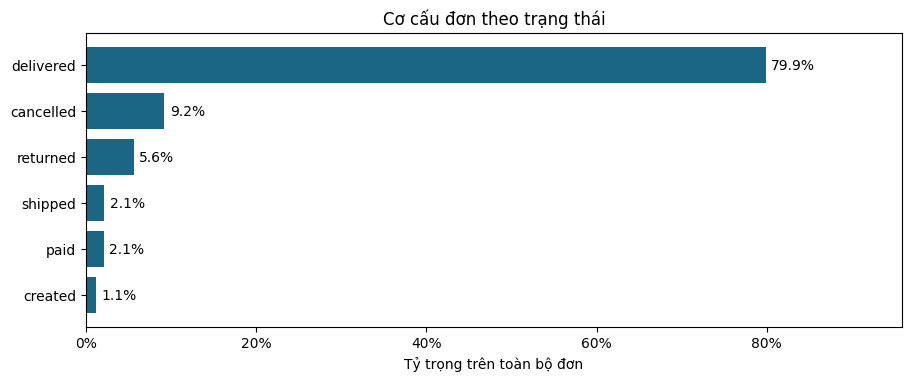

**Đơn đã giao chiếm 79.9% tổng số đơn.** Các lát cắt về giá trị mua sau đây dùng nhóm đã giao.

In [28]:
if orders["order_id"].isna().any() or not orders["order_id"].is_unique:
    raise ValueError("Bảng orders_common phải có một dòng cho mỗi mã đơn hợp lệ.")

orders["net_amount"] = orders["net_amount"].map(Decimal, na_action="ignore")
orders["net_cents"] = orders["net_amount"].map(exact_cents, na_action="ignore").astype("Int64")
status = orders.groupby("order_status", dropna=False).agg(
    so_don=("order_id", "size"),
    so_don_co_net=("net_cents", "count"),
    net_cents=("net_cents", lambda values: values.sum(min_count=1)),
).sort_values("so_don", ascending=False)
status["ty_trong"] = status["so_don"] / len(orders)
status_view = status.assign(
    **{"Net (triệu ĐVT nguồn)": (status["net_cents"] / 1e8).round(2),
       "Tỷ trọng số đơn (%)": (100 * status["ty_trong"]).round(2)}
).drop(columns=["net_cents", "ty_trong"]).rename(
    columns={"so_don": "Số đơn", "so_don_co_net": "Đơn có Net"},
)
display(status_view.rename_axis("Trạng thái"))

fig, ax = plt.subplots(figsize=(9, 3.7), layout="constrained")
shares_by_status = status["ty_trong"].sort_values()
bars = ax.barh(shares_by_status.index.astype(str), shares_by_status, color="#1c6685")
ax.bar_label(bars, [f"{v:.1%}" for v in shares_by_status], padding=4)
ax.set(xlim=(0, min(1.1, shares_by_status.max() * 1.2)),
       xlabel="Tỷ trọng trên toàn bộ đơn", title="Cơ cấu đơn theo trạng thái")
ax.xaxis.set_major_formatter(PercentFormatter(1))
display(fig)
plt.close(fig)

delivered_share = status.loc["delivered", "ty_trong"]
display(Markdown(f"**Đơn đã giao chiếm {delivered_share:.1%} tổng số đơn.** "
                 "Các lát cắt về giá trị mua sau đây dùng nhóm đã giao."))

## 2. So sánh theo nhóm và thời gian

### Ngành hàng nào đóng góp lượng bán và Net?

Lọc các dòng hàng có trạng thái `delivered`, rồi cộng số lượng và Net theo `category`. Hai tỷ trọng trả lời hai câu hỏi khác nhau: ngành nào bán nhiều đơn vị hàng, và ngành nào chiếm nhiều giá trị Net.

,Số lượng,Net (triệu ĐVT nguồn),Tỷ trọng số lượng (%),Tỷ trọng Net (%)
Ngành hàng,,,,
Streetwear,1413433,10030.05,55.08,80.12
Outdoor,933785,1875.83,36.39,14.98
Casual,85457,349.09,3.33,2.79
GenZ,133255,263.2,5.19,2.1


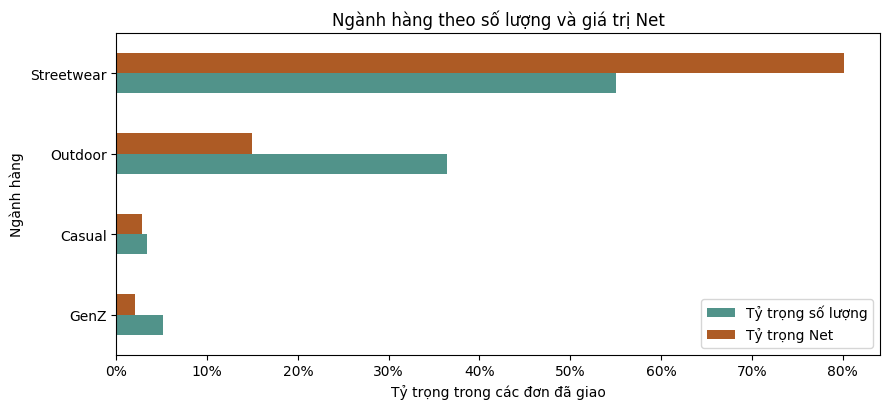

**Streetwear** đứng đầu theo Net với **80.1%** giá trị, so với **55.1%** số lượng. Hai tỷ trọng được tính trên cùng phạm vi đơn đã giao.

In [29]:
delivered = orders.loc[orders["order_status"].eq("delivered")].copy()
delivered_lines = items.loc[items["order_status"].eq("delivered")].copy()
delivered_lines["net_cents"] = delivered_lines["line_net"].map(
    lambda value: exact_cents(Decimal(value)), na_action="ignore"
).astype("Int64")
if delivered_lines["net_cents"].isna().any() or delivered["net_cents"].isna().any():
    raise ValueError("Phạm vi đơn đã giao có dòng thiếu Net, cần xem lại đầu ra GD2.")
if delivered_lines["net_cents"].sum() != delivered["net_cents"].sum():
    raise ValueError("Tổng Net của đơn đã giao lệch giữa bảng cấp đơn và cấp dòng hàng.")

category = delivered_lines.groupby("category", dropna=False).agg(
    units=("quantity", "sum"), net_cents=("net_cents", "sum"),
).sort_values("net_cents", ascending=False)
category["unit_share"] = category["units"] / category["units"].sum()
category["net_share"] = category["net_cents"] / category["net_cents"].sum()
display(pd.DataFrame({
    "Số lượng": category["units"],
    "Net (triệu ĐVT nguồn)": (category["net_cents"] / 1e8).round(2),
    "Tỷ trọng số lượng (%)": (category["unit_share"] * 100).round(2),
    "Tỷ trọng Net (%)": (category["net_share"] * 100).round(2),
}).rename_axis("Ngành hàng"))

ax = category[["unit_share", "net_share"]].sort_values("net_share").rename(columns={
    "unit_share": "Tỷ trọng số lượng", "net_share": "Tỷ trọng Net",
}).plot.barh(figsize=(9, 4.2), color=["#51938a", "#ad5b25"])
ax.set(xlabel="Tỷ trọng trong các đơn đã giao", ylabel="Ngành hàng",
       title="Ngành hàng theo số lượng và giá trị Net")
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.legend(loc="lower right")
plt.tight_layout()
display(ax.figure)
plt.close(ax.figure)

top_category = category.index[0]
display(Markdown(f"**{top_category}** đứng đầu theo Net với "
                 f"**{category.at[top_category, 'net_share']:.1%}** giá trị, "
                 f"so với **{category.at[top_category, 'unit_share']:.1%}** số lượng. "
                 "Hai tỷ trọng được tính trên cùng phạm vi đơn đã giao."))

### Khách mua bao nhiêu lần và chi tiêu ra sao?

Dùng đơn đã giao đến ngày chốt 31/12/2022 để xem lần mua gần nhất, số đơn và tổng Net của từng khách. Ba đại lượng này lần lượt là **Recency**, **Frequency** và **Monetary**. Bảng độ phủ cho thấy nhóm khách được đưa vào phân phối chiếm bao nhiêu trong danh mục.

In [30]:
eligible_orders = delivered.loc[delivered[date_col].le(cutoff)].rename(
    columns={date_col: "order_date"}
)
rfm = rfm_tools.rfm(eligible_orders, cutoff=cutoff)
catalog_customers = pd.Index(customers["customer_id"].dropna().unique())
known_buyers = pd.Index(orders.loc[orders[date_col].le(cutoff), "customer_id"].dropna().unique())
eligible_customers = pd.Index(rfm["customer_id"])
if not eligible_customers.isin(catalog_customers).all():
    raise ValueError("Có mã khách đủ điều kiện RFM nằm ngoài bảng customers.csv.")

coverage = pd.Series({
    "Có đơn đã giao đủ điều kiện RFM": len(eligible_customers),
    "Có đơn, chưa đủ điều kiện RFM": len(catalog_customers.intersection(known_buyers).difference(eligible_customers)),
    "Không thấy đơn đến ngày chốt": len(catalog_customers.difference(known_buyers)),
}, name="Số khách")
display(coverage.to_frame().assign(**{
    "Tỷ trọng trên danh mục (%)": (100 * coverage / len(catalog_customers)).round(2)
}))
display(Markdown(f"Tập RFM bao phủ **{len(rfm):,}/{len(catalog_customers):,} khách** "
                 f"(**{len(rfm)/len(catalog_customers):.1%}**). "
                 "Các phân phối bên dưới lấy mẫu số là số khách đủ điều kiện."))

,Số khách,Tỷ trọng trên danh mục (%)
Có đơn đã giao đủ điều kiện RFM,85115,69.81
"Có đơn, chưa đủ điều kiện RFM",5131,4.21
Không thấy đơn đến ngày chốt,31684,25.99


Tập RFM bao phủ **85,115/121,930 khách** (**69.8%**). Các phân phối bên dưới lấy mẫu số là số khách đủ điều kiện.

,P25,Trung vị,P75,P95
Recency (ngày),395.00,1142.00,2046.00,3289.00
Frequency (đơn),1.00,3.00,8.00,20.00
Monetary (ĐVT nguồn),28544.99,79730.85,198288.88,513558.65


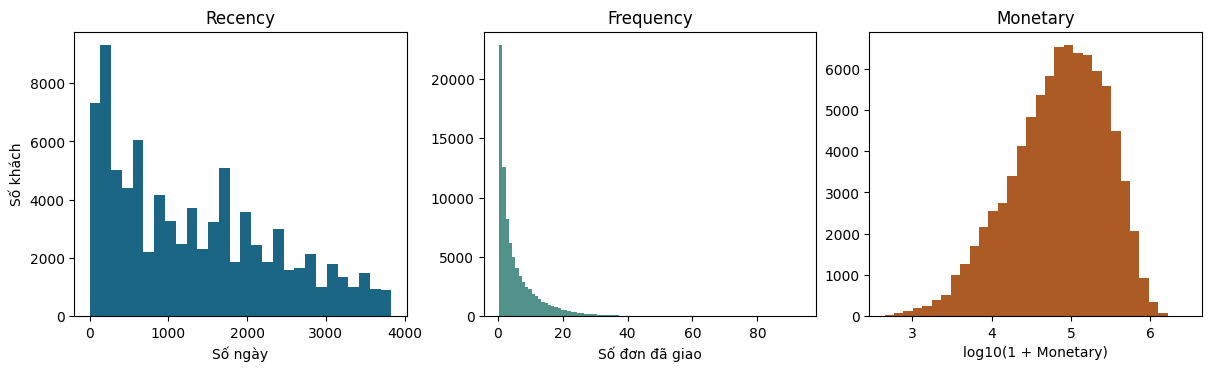

**26.8%** khách trong tập quan sát chỉ có một đơn đã giao. Frequency trung vị là **3 đơn**, còn P95 là **20 đơn**. Trục log của Monetary chỉ giúp quan sát đuôi phân phối trong biểu đồ.

In [31]:
values = rfm[["Recency", "Frequency", "Monetary"]].astype(float)
summary = values.quantile([0.25, 0.5, 0.75, 0.95]).T.rename(columns={
    0.25: "P25", 0.5: "Trung vị", 0.75: "P75", 0.95: "P95",
})
display(summary.round(2).rename(index={
    "Recency": "Recency (ngày)", "Frequency": "Frequency (đơn)", "Monetary": "Monetary (ĐVT nguồn)",
}))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), layout="constrained")
axes[0].hist(values["Recency"], bins=28, color="#1c6685")
axes[0].set(xlabel="Số ngày", ylabel="Số khách", title="Recency")
axes[1].hist(values["Frequency"], bins=np.arange(0.5, values["Frequency"].max() + 1.5),
             color="#51938a")
axes[1].set(xlabel="Số đơn đã giao", title="Frequency")
axes[2].hist(np.log10(1 + values["Monetary"]), bins=32, color="#ad5b25")
axes[2].set(xlabel="log10(1 + Monetary)", title="Monetary")
display(fig)
plt.close(fig)

one_order_share = rfm["Frequency"].eq(1).mean()
display(Markdown(f"**{one_order_share:.1%}** khách trong tập quan sát chỉ có một đơn đã giao. "
                 f"Frequency trung vị là **{summary.loc['Frequency', 'Trung vị']:.0f} đơn**, "
                 f"còn P95 là **{summary.loc['Frequency', 'P95']:.0f} đơn**. "
                 "Trục log của Monetary chỉ giúp quan sát đuôi phân phối trong biểu đồ."))

,Nhóm khách đứng đầu (%),Số khách,Tỷ trọng Monetary (%)
0,1,852,7.07
1,5,4256,24.24
2,10,8512,39.10
3,20,17023,59.51
4,50,42558,88.98


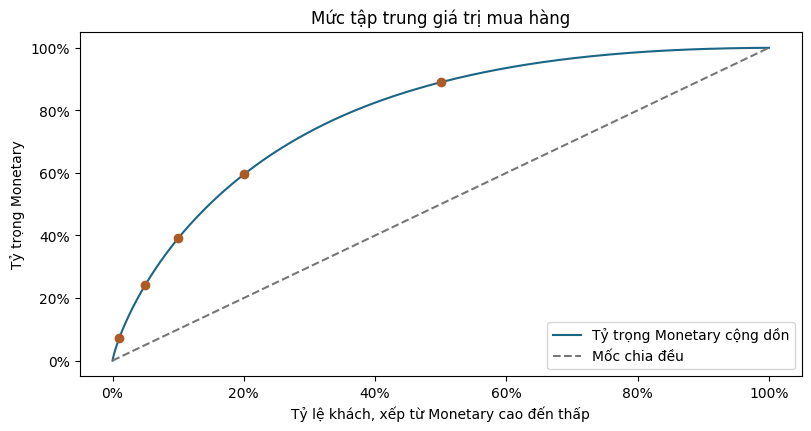

**20% khách có Monetary cao nhất đóng góp 59.5% tổng Monetary** của tập khách có đơn đã giao đến ngày chốt.

In [32]:
monetary_cents = rfm["Monetary"].map(exact_cents).sort_values(ascending=False).to_numpy()
cumulative = np.r_[0, monetary_cents.cumsum()] / monetary_cents.sum()
fractions = np.array([0.01, 0.05, 0.10, 0.20, 0.50])
top_counts = np.ceil(fractions * len(rfm)).astype(int)
top_share = cumulative[top_counts]
display(pd.DataFrame({
    "Nhóm khách đứng đầu (%)": (100 * fractions).astype(int),
    "Số khách": top_counts,
    "Tỷ trọng Monetary (%)": (100 * top_share).round(2),
}))

fig, ax = plt.subplots(figsize=(8, 4.2), layout="constrained")
ax.plot(np.arange(len(cumulative)) / len(rfm), cumulative, color="#1c6685",
        label="Tỷ trọng Monetary cộng dồn")
ax.plot([0, 1], [0, 1], "--", color="#777777", label="Mốc chia đều")
ax.scatter(top_counts / len(rfm), top_share, color="#ad5b25", zorder=3)
ax.set(xlabel="Tỷ lệ khách, xếp từ Monetary cao đến thấp",
       ylabel="Tỷ trọng Monetary", title="Mức tập trung giá trị mua hàng")
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.legend(loc="lower right")
display(fig)
plt.close(fig)

display(Markdown(f"**20% khách có Monetary cao nhất đóng góp {top_share[3]:.1%} tổng Monetary** "
                 "của tập khách có đơn đã giao đến ngày chốt."))

### Revenue và COGS thay đổi ra sao theo tháng?

Kiểm tra lịch từng ngày trước khi cộng theo tháng. Tháng thiếu ngày quan sát được đánh dấu để tránh so trực tiếp với tháng đầy đủ. Revenue và COGS dùng theo định nghĩa của `sales.csv`. Chênh lệch giữa hai cột chưa đủ để kết luận lợi nhuận thực tế.

,Từ ngày,Đến ngày,Số ngày quan sát,Ngày thiếu giữa hai đầu mốc,Dòng trùng ngày (dư),Ngày COGS > Revenue
0,2012-07-04,2022-12-31,3833,0,0,382


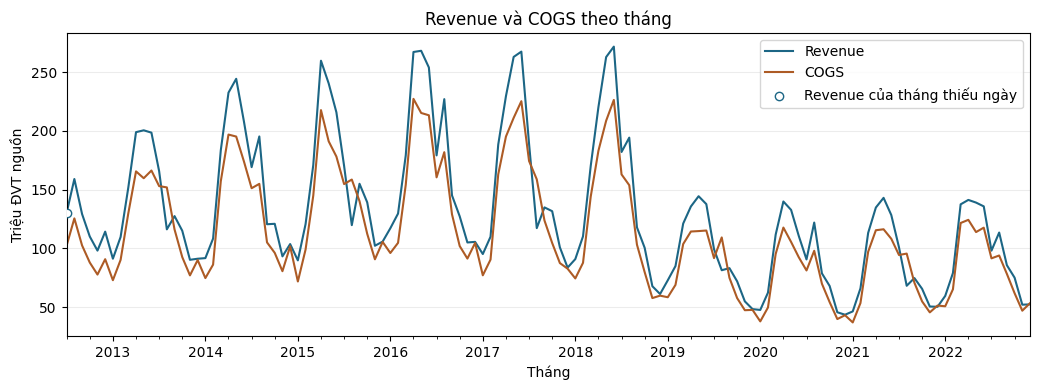

**2018-06** có Revenue cao nhất trong các tháng đủ ngày. Tháng thiếu ngày quan sát: **2012-07**. COGS cao hơn Revenue ở **382/3,833 ngày**.

In [33]:
expected_days = pd.date_range(sales["Date"].min(), sales["Date"].max(), freq="D")
missing_days = expected_days.difference(sales["Date"])
repeat_dates = int(sales["Date"].duplicated().sum())
cogs_above = int(sales["COGS"].gt(sales["Revenue"]).sum())
display(pd.DataFrame([{
    "Từ ngày": sales["Date"].min().date(),
    "Đến ngày": sales["Date"].max().date(),
    "Số ngày quan sát": sales["Date"].nunique(),
    "Ngày thiếu giữa hai đầu mốc": len(missing_days),
    "Dòng trùng ngày (dư)": repeat_dates,
    "Ngày COGS > Revenue": cogs_above,
}]))
if repeat_dates or sales[["Date", "Revenue", "COGS"]].isna().any().any():
    raise ValueError("sales.csv có ngày trùng hoặc thiếu giá trị, cần kiểm chứng lại ở V09.")

monthly = sales.groupby(sales["Date"].dt.to_period("M")).agg(
    Revenue=("Revenue", "sum"), COGS=("COGS", "sum"), observed_days=("Date", "size")
)
partial = monthly["observed_days"].ne(monthly.index.days_in_month)
peak_full_month = monthly.loc[~partial, "Revenue"].idxmax()
chart = monthly[["Revenue", "COGS"]].set_axis(monthly.index.to_timestamp()) / 1_000_000
ax = chart.plot(figsize=(10.5, 4), linewidth=1.5, color=["#1c6685", "#ad5b25"])
if partial.any():
    partial_chart = chart.loc[partial.to_numpy()]
    ax.scatter(partial_chart.index, partial_chart["Revenue"], facecolors="white",
               edgecolors="#1c6685", label="Revenue của tháng thiếu ngày", zorder=3)
ax.set(title="Revenue và COGS theo tháng", xlabel="Tháng", ylabel="Triệu ĐVT nguồn")
ax.grid(axis="y", alpha=0.23)
ax.legend()
plt.tight_layout()
display(ax.figure)
plt.close(ax.figure)

partial_months = ", ".join(monthly.index[partial].astype(str)) or "không có"
display(Markdown(f"**{peak_full_month}** có Revenue cao nhất trong các tháng đủ ngày. "
                 f"Tháng thiếu ngày quan sát: **{partial_months}**. "
                 f"COGS cao hơn Revenue ở **{cogs_above:,}/{len(sales):,} ngày**."))

## 3. Đào sâu hai điểm chênh

### Khoảng chênh giữa tỷ trọng lượng bán và tỷ trọng Net tập trung ở đâu?

Chọn ngành hàng có tỷ trọng Net thấp hơn tỷ trọng số lượng nhiều nhất, sau đó nhìn vào các sản phẩm bán nhiều trong ngành đó. Net trên mỗi đơn vị là tổng Net chia tổng số lượng. Chỉ tiêu này chịu ảnh hưởng của cả giá và giảm giá.

In [34]:
gap = category["net_share"] - category["unit_share"]
focus = gap.idxmin()
focus_lines = delivered_lines.loc[delivered_lines["category"].eq(focus)]
products = focus_lines.groupby("product_id", dropna=False).agg(
    units=("quantity", "sum"), net_cents=("net_cents", "sum"),
).sort_values("units", ascending=False, kind="stable")
overall_unit_net = delivered_lines["net_cents"].sum() / (100 * delivered_lines["quantity"].sum())
focus_unit_net = focus_lines["net_cents"].sum() / (100 * focus_lines["quantity"].sum())
top_products = products.head(6)
display(pd.DataFrame({
    "Số lượng": top_products["units"],
    "Tỷ trọng lượng trong ngành (%)": (top_products["units"] * 100 / products["units"].sum()).round(2),
    "Net mỗi đơn vị (ĐVT nguồn)": (top_products["net_cents"] / (100 * top_products["units"])).round(2),
}).rename_axis("Mã sản phẩm"))
display(Markdown(f"**{focus}** có tỷ trọng Net thấp hơn tỷ trọng số lượng "
                 f"**{-gap.loc[focus]*100:.2f} điểm phần trăm**. "
                 f"Net bình quân mỗi đơn vị là **{focus_unit_net:,.2f} ĐVT** trong ngành này "
                 f"và **{overall_unit_net:,.2f} ĐVT** trên toàn bộ dòng hàng đã giao. "
                 "Bảng trên cho thấy mức Net ở các sản phẩm bán nhiều nhất trong ngành."))

,Số lượng,Tỷ trọng lượng trong ngành (%),Net mỗi đơn vị (ĐVT nguồn)
Mã sản phẩm,,,
791,36517,3.91,679.17
792,35988,3.85,679.37
734,18112,1.94,3933.14
733,17974,1.92,3932.01
1086,17838,1.91,997.51
1085,17729,1.90,994.54


**Outdoor** có tỷ trọng Net thấp hơn tỷ trọng số lượng **21.41 điểm phần trăm**. Net bình quân mỗi đơn vị là **2,008.84 ĐVT** trong ngành này và **4,878.61 ĐVT** trên toàn bộ dòng hàng đã giao. Bảng trên cho thấy mức Net ở các sản phẩm bán nhiều nhất trong ngành.

### Ngày trong tuần có khác biệt không?

So trung vị và khoảng P25–P75 giữa các ngày trong tuần. Khoảng này chứa nửa giữa của các quan sát lịch sử. Sự khác biệt quan sát được giữa các ngày là một dấu hiệu cần kiểm tra thêm giữa các năm.

,Số ngày,Revenue trung vị (triệu),COGS trung vị (triệu)
Ngày trong tuần,,,
Thứ 2,547,3.85,3.29
Thứ 3,547,3.93,3.33
Thứ 4,548,3.93,3.48
Thứ 5,548,3.63,3.27
Thứ 6,548,3.36,2.86
Thứ 7,548,3.38,2.89
Chủ nhật,547,3.60,3.09


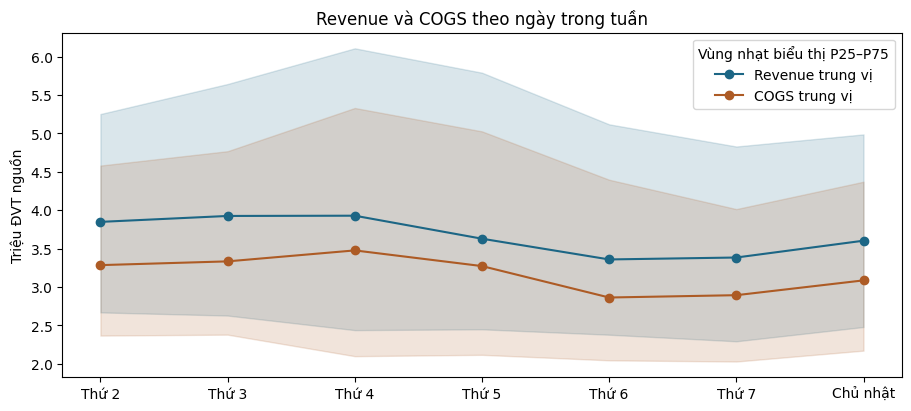

Revenue trung vị cao nhất vào **Thứ 4** (**3.93 triệu ĐVT**) và thấp nhất vào **Thứ 6** (**3.36 triệu ĐVT**). Các dải P25–P75 giúp xem mức độ dao động bên trong từng ngày.

In [35]:
weekday_names = ["Thứ 2", "Thứ 3", "Thứ 4", "Thứ 5", "Thứ 6", "Thứ 7", "Chủ nhật"]
daily_group = sales.groupby(sales["Date"].dt.dayofweek)
weekday = daily_group[["Revenue", "COGS"]].median().reindex(range(7))
weekday.index = weekday_names
table = (weekday / 1_000_000).rename(columns={
    "Revenue": "Revenue trung vị (triệu)", "COGS": "COGS trung vị (triệu)",
})
table.insert(0, "Số ngày", daily_group.size().reindex(range(7)).to_numpy())
display(table.round(2).rename_axis("Ngày trong tuần"))

x = np.arange(7)
fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
for name, color in [("Revenue", "#1c6685"), ("COGS", "#ad5b25")]:
    quartiles = daily_group[name].quantile([0.25, 0.75]).unstack().reindex(range(7)) / 1_000_000
    ax.plot(x, weekday[name].to_numpy() / 1_000_000, "o-", color=color, label=f"{name} trung vị")
    ax.fill_between(x, quartiles[0.25].to_numpy(), quartiles[0.75].to_numpy(),
                    color=color, alpha=0.16)
ax.set_xticks(x, weekday_names)
ax.set(title="Revenue và COGS theo ngày trong tuần", ylabel="Triệu ĐVT nguồn")
ax.legend(title="Vùng nhạt biểu thị P25–P75")
display(fig)
plt.close(fig)

high_day, low_day = weekday["Revenue"].idxmax(), weekday["Revenue"].idxmin()
display(Markdown(f"Revenue trung vị cao nhất vào **{high_day}** "
                 f"(**{weekday.loc[high_day, 'Revenue']/1e6:.2f} triệu ĐVT**) "
                 f"và thấp nhất vào **{low_day}** "
                 f"(**{weekday.loc[low_day, 'Revenue']/1e6:.2f} triệu ĐVT**). "
                 "Các dải P25–P75 giúp xem mức độ dao động bên trong từng ngày."))

In [36]:
# So lại hai thứ có trung vị cao và thấp nhất trong từng năm đủ lịch.
sales_by_year = sales.assign(year=sales["Date"].dt.year, weekday=sales["Date"].dt.dayofweek)
year_sizes = sales_by_year.groupby("year")["Date"].size()
expected_by_year = pd.Series({
    y: 366 if pd.Timestamp(y, 1, 1).is_leap_year else 365 for y in year_sizes.index
})
full_years = year_sizes.index[year_sizes.eq(expected_by_year)]
weekday_pairs = sales_by_year.loc[
    sales_by_year["year"].isin(full_years) &
    sales_by_year["weekday"].isin([weekday_names.index(high_day), weekday_names.index(low_day)])
].pivot_table(index="year", columns="weekday", values="Revenue", aggfunc="median")
annual_gap = weekday_pairs[weekday_names.index(high_day)] - weekday_pairs[weekday_names.index(low_day)]
higher_years = annual_gap.gt(0).sum()
display((annual_gap / 1_000_000).round(2).rename(
    f"Revenue trung vị {high_day} trừ {low_day} (triệu ĐVT)"
).to_frame().rename_axis("Năm đủ lịch"))
display(Markdown(f"**{high_day}** có trung vị cao hơn **{low_day}** trong "
                 f"**{higher_years}/{len(annual_gap)} năm đủ lịch**. "
                 "Đây là phép kiểm mô tả trên lịch sử để xem chênh lệch có lặp lại qua các năm."))

,Revenue trung vị Thứ 4 trừ Thứ 6 (triệu ĐVT)
Năm đủ lịch,
2013,1.14
2014,1.96
2015,0.05
2016,-0.16
2017,0.71
2018,0.95
2019,0.69
2020,0.13
2021,0.15


**Thứ 4** có trung vị cao hơn **Thứ 6** trong **9/10 năm đủ lịch**. Đây là phép kiểm mô tả trên lịch sử để xem chênh lệch có lặp lại qua các năm.

## 4. Rút câu hỏi từ kết quả

Các nhận định dưới đây tóm tắt số liệu vừa tính. Cột cuối ghi điều cần kiểm tra thêm để giải thích quan sát hoặc đánh giá khả năng sử dụng nó.

In [37]:
display(pd.DataFrame([
    {
        "Quan sát": f"{focus} chiếm {category.at[focus, 'unit_share']:.1%} lượng bán "
                    f"và {category.at[focus, 'net_share']:.1%} Net của đơn đã giao.",
        "Câu hỏi tiếp": "Chênh lệch đến từ giá bán, giảm giá hay cơ cấu sản phẩm?",
        "Cần xem thêm": "Tách đơn giá và chiết khấu theo nhóm sản phẩm và thời kỳ.",
    },
    {
        "Quan sát": f"{one_order_share:.1%} khách có một đơn đã giao. "
                    f"Top 20% khách đóng góp {top_share[3]:.1%} tổng Monetary.",
        "Câu hỏi tiếp": "Có nhóm hành vi mua khác nhau và ổn định qua các cách phân nhóm không?",
        "Cần xem thêm": "So sánh phân phối, độ tách và độ ổn định khi thay đổi cách xử lý đặc trưng.",
    },
    {
        "Quan sát": f"Revenue trung vị {high_day} cao hơn {low_day} trong "
                    f"{higher_years}/{len(annual_gap)} năm đủ lịch.",
        "Câu hỏi tiếp": "Thông tin về thứ trong tuần có giúp dự báo ngày chưa thấy không?",
        "Cần xem thêm": "Đánh giá trên các giai đoạn xác thực sau thời điểm huấn luyện.",
    },
]))

,Quan sát,Câu hỏi tiếp,Cần xem thêm
0,Outdoor chiếm 36.4% lượng bán và 15.0% Net của...,"Chênh lệch đến từ giá bán, giảm giá hay cơ cấu...",Tách đơn giá và chiết khấu theo nhóm sản phẩm ...
1,26.8% khách có một đơn đã giao. Top 20% khách ...,Có nhóm hành vi mua khác nhau và ổn định qua c...,"So sánh phân phối, độ tách và độ ổn định khi t..."
2,Revenue trung vị Thứ 4 cao hơn Thứ 6 trong 9/1...,Thông tin về thứ trong tuần có giúp dự báo ngà...,Đánh giá trên các giai đoạn xác thực sau thời ...
